# **Multi-Building Design Update of CLT buildings**

This Jupyter Notebook demonstrates how to use the joint **Multi-Model Update** with the example of two, previously trained models of two Tall Timber Buildings: the Yoker and Palisaden buildings (see the notebook on Hybrid Digital Twinning of the Yoker Building [here](https://buildchain.ilab.sztaki.hu/notebooks/1_hybrid_digital_twinning/hybrid_Yoker.html)).

The main objective of the Multi-Building Updating is to calibrate uncertain parameters of simulation models across multiple buildings or experimental setups using shared measurement data. This ensemble-based calibration improves generalizability and robustness compared to single-structure updates.


In [1]:
import sys
import os
parent_dir = os.path.abspath("../../libraries/surrogate_modelling")
sys.path.insert(0, parent_dir)

In [2]:
import pickle
import pandas as pd
import utils
from multibuilding_update import JointManager

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Load models

In this example we simply load two previusly trained hybrid models of the two system. The chosen parameters of the models were the following:

- Yoker: elastic moduli of the CLT panels in the three major strength directions ($e_{1}$, $e_{2}$, $e_{3}$), two in-plane shear moduli ($g_{1}$, $g_{2}$) and the distributed mass ($q$).
- Palisaden: scaling factor for the vertical elastic moduli of the CLT walls ($γ_{e_{1}}$), scaling factor for the in-plane shear stiffness of the walls ($γ_{G_{12}}$), additional scaling factor used for the external walls to  account for the increased  shear stiffness of these walls due to the facade ($γ_{G_{12,ext}}$), stiffness parameter of the foundation beneath the ground floor ($k_{spring}$) and a scaling factor of the initially estimated total mass of the building ($γ_{ρ}$)

The models are connected through the **$e_{1}$** and $γ_{e_{1}}$ parameters

In [3]:
#Load measurement data
z_yoker = pd.read_csv('../data/YB_data/z_m_df.csv')
z_palisaden = pd.read_csv('../data/PS_data/z_m_df.csv')

#Load standard deviation of the measurement error
sigma_yoker = pd.read_csv('../data/YB_data/sigma.csv')
sigma_palisaden = pd.read_csv('../data/PS_data/sigma.csv')

#Load surrogate models
with open('../data/YB_data/Yoker_model.sm', 'rb') as file:
    Yoker_model = pickle.load(file)
with open('../data/PS_data/Palisaden_model.sm', 'rb') as file:
    Palisaden_model = pickle.load(file)

# Update

In [4]:
#Define joint parameters
joint_parameters = {'joint_e1_COEF_VERT': ['e1', 'COEF_VERT']}

#Define the joint manager
j = JointManager([Yoker_model, Palisaden_model], joint_parameters)
print(j.Q.params)

{'joint_e1_COEF_VERT': U(0, 1), 'e2': U(10, 13), 'e3': U(6, 12), 'g1': U(400, 750), 'g2': U(200, 500), 'q': U(5, 100), 'COEF_G': U(1, 3), 'FACADE': U(1, 1.5), 'FOUNDATION': U(7, 10), 'WEIGHT': U(0.8, 1.2)}


In [5]:
nwalkers=32
niter=200
nburn=1000


j.update([z_yoker, z_palisaden], [sigma_yoker, sigma_palisaden], nwalkers=nwalkers, niter=niter, nburn=nburn)

MCMC creating
Burning period


100%|██████████| 1000/1000 [02:43<00:00,  6.13it/s]


MCMC running


100%|██████████| 200/200 [00:32<00:00,  6.20it/s]

--- 195.59718489646912 seconds ---


# Results

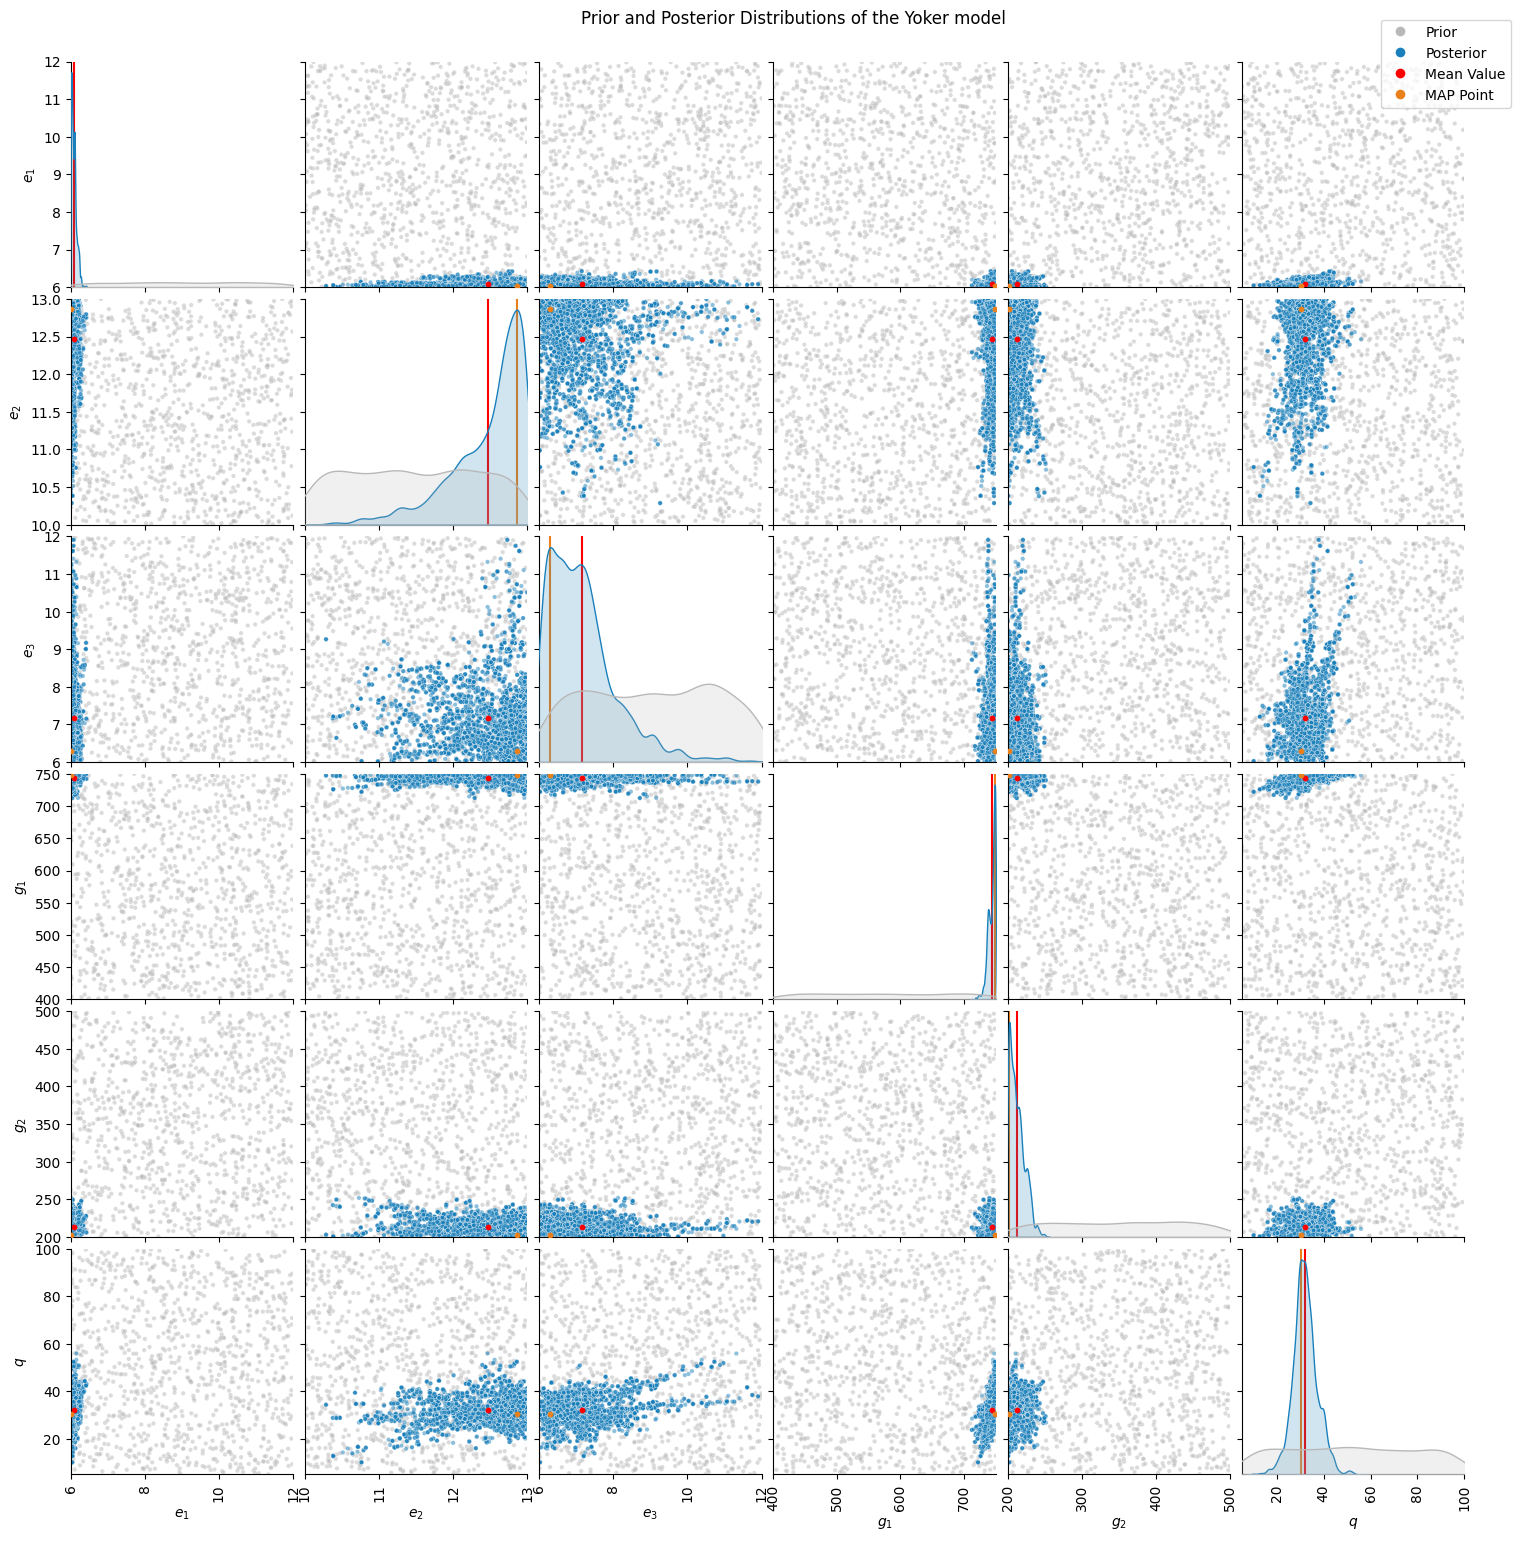

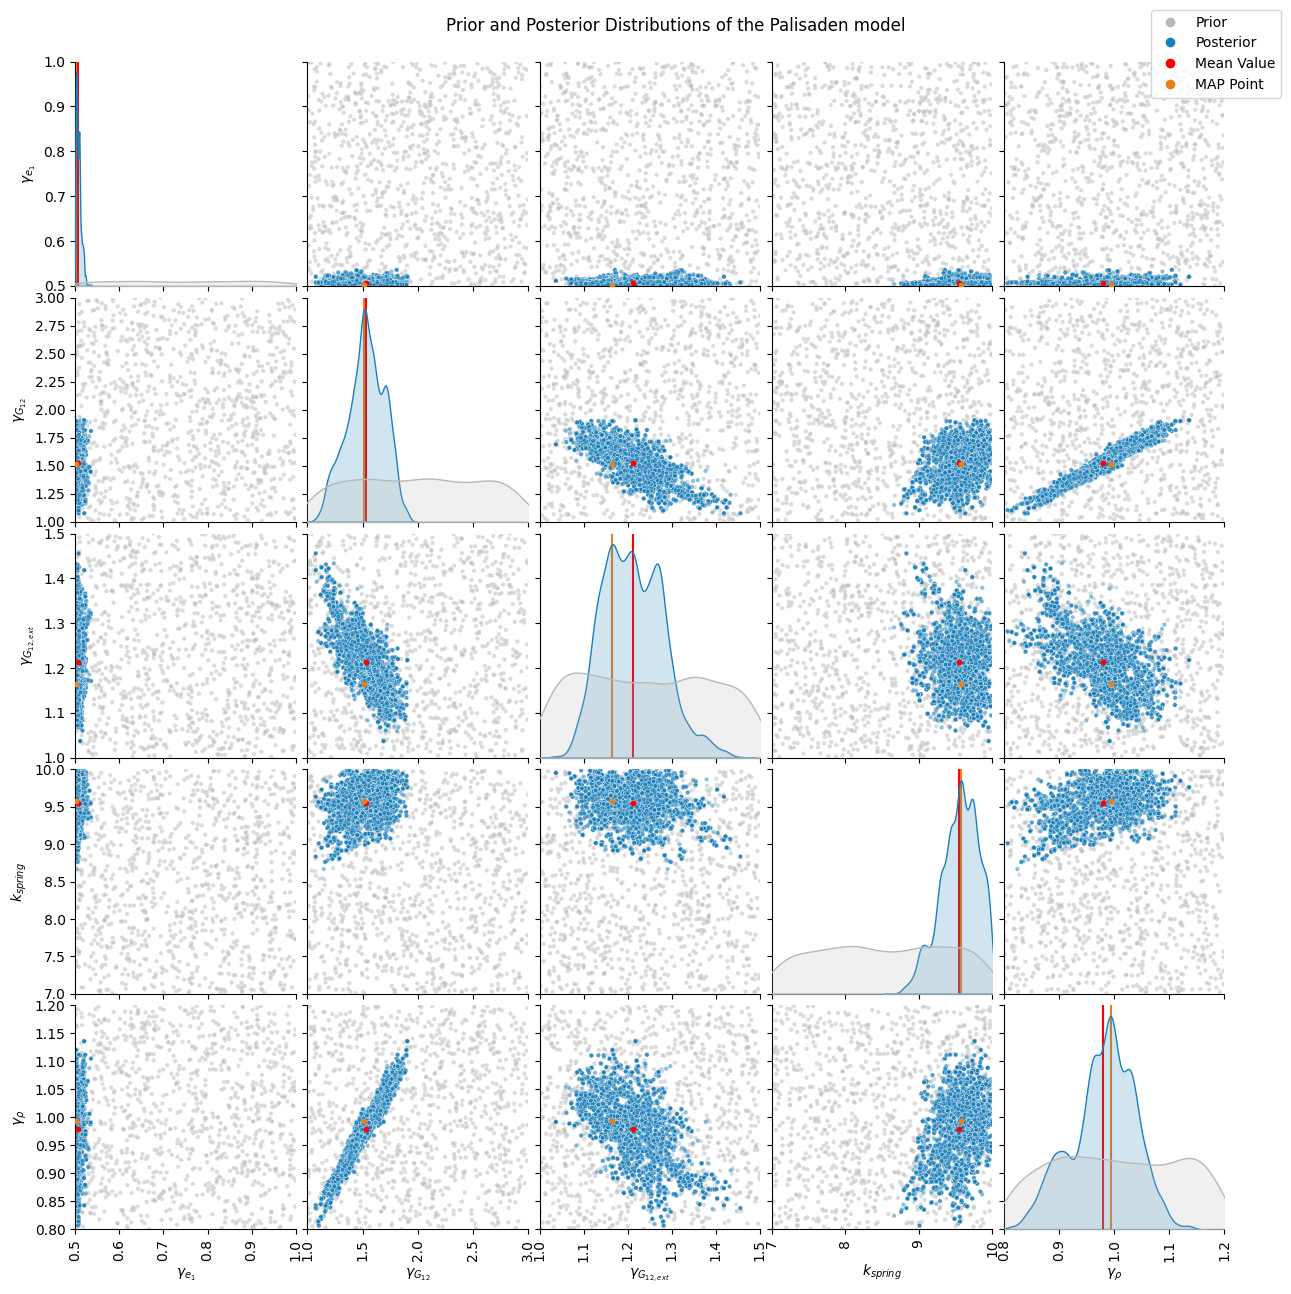

In [6]:
figs = utils.plot_multibuilding_MCMC(j, map_point=True, model_names=['Yoker', 'Palisaden'], formatted_param_names=[["$e_{1}$", "$e_{2}$", "$e_{3}$", "$g_{1}$", "$g_{2}$", '$q$'], ["$γ_{e_{1}}$", "$γ_{G_{12}}$", "$γ_{G_{12,ext}}$", "$k_{spring}$", "$γ_{ρ}$"]])

In [7]:
model_index = 0
map_point, mean, variance, posterior_samples = j.get_data_of_model(model_index)

In [8]:
map_point

,e1,e2,e3,g1,g2,q
0,6.02171,12.862627,6.303979,748.478029,202.347768,30.322943


In [9]:
mean

,e1,e2,e3,g1,g2,q
0,6.086066,12.470402,7.165949,743.289847,212.588295,31.945209


In [10]:
variance

,e1,e2,e3,g1,g2,q
0,0.000776,0.251166,0.864418,34.816165,100.797708,27.898598


In [11]:
posterior_samples

,e1,e2,e3,g1,g2,q
0,6.112028,12.726165,6.564941,739.738715,208.829853,29.094813
1,6.153240,12.592408,7.716141,747.670196,222.585328,36.009400
2,6.018032,11.812395,7.454997,742.444707,231.997122,34.767694
3,6.060164,12.891006,11.611621,738.432315,221.959850,41.648507
4,6.014331,12.881255,9.764288,735.385113,200.020074,32.023439
...,...,...,...,...,...,...
6395,6.138696,12.492959,7.369379,744.866998,203.682742,31.057208
6396,6.046991,12.701343,7.055535,746.922873,215.005895,30.875464
6397,6.271969,12.553050,6.249253,736.862987,208.898018,26.739309
6398,6.044689,11.284199,7.514824,745.909966,206.084792,33.245219
